# Measured canine gait — upper-arm vs forearm virtual IMU

This notebook uses **only the uploaded tracked landmarks** to construct the empirical gait reference and virtual IMU signals. It compares phase estimates from the upper arm and the forearm using two cycles, each tested against a reference built from the other cycle. The right prosthetic motion is **not independently measured**: it is the extracted walking trajectory shifted by an assumed half-cycle.

The CSV does not specify a physical scale or video frame rate. Distances are normalized by median measured forearm length, and angular velocities are calculated per recorded frame. `fps` affects GIF playback only. The one-degree image rotation is an approximate, optional correction. Data are noisy and marker-tracking artifacts remain.

Place `dog_positions(Sheet1) (1).csv` in the same directory as this notebook. LaTeX needs a functioning TeX installation (comment out `usetex=True` if necessary).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML

plt.rc("font", family="serif", size=10)
plt.rc('text', usetex=True)

# Read and lightly smooth the four tracked landmarks.
df = pd.read_csv("dog_positions.csv")
df.columns = df.columns.str.strip()
frames = df["Frame"].to_numpy()
for color in ["Blue", "Red", "Yellow", "Green"]:
    for axis in "XY":
        col = color + axis
        df[col] = df[col].rolling(3, center=True, min_periods=1).median()
        df[col] = df[col].rolling(3, center=True, min_periods=1).mean()

# Shoulder-relative coordinates, with image y inverted to point upward.
points = {}
for color in ["Red", "Yellow", "Green"]:
    points[color] = np.column_stack((
        df[color + "X"] - df["BlueX"],
        df["BlueY"] - df[color + "Y"]
    ))

# Approximate camera rotation (in degrees); set 0 if correction is unwanted.
tilt = np.deg2rad(1.0)
rotation = np.array([[np.cos(tilt), -np.sin(tilt)],
                     [np.sin(tilt),  np.cos(tilt)]])
points = {name: xy @ rotation.T for name, xy in points.items()}

# Normalize by the median measured forearm length: L2 = 1 unit.
scale = np.median(np.linalg.norm(points["Yellow"] - points["Red"], axis=1))
elbow = points["Red"] / scale
wrist = points["Yellow"] / scale
toe = points["Green"] / scale
L1 = np.median(np.linalg.norm(elbow, axis=1))
L2 = 1.0
L3 = np.median(np.linalg.norm(toe - wrist, axis=1))

# Two complete cycles, chosen from the toe's forward-most positions.
cycle_bounds = [(11, 29), (29, 50)]
frame_ids = np.arange(11, 50)  # includes two cycles; excludes partial ends
n_frames = len(frame_ids)
s_left_true = np.interp(frame_ids, [11, 29, 50], [0, 1, 2]) % 1
phase_grid = np.linspace(0, 1, 120, endpoint=False)
fps = 20  # GIF display rate only; the CSV does not specify video fps.

print(f"Normalized link lengths: {L1:.3f}, {L2:.3f}, {L3:.3f}")

Normalized link lengths: 0.858, 1.000, 0.539


In [2]:
def inverse_kinematics_3link(x, y, phi, L1, L2, L3, elbow_sign=1):
    """Desired toe position and paw angle -> three joint angles."""
    xw = np.asarray(x) - L3 * np.cos(phi)
    yw = np.asarray(y) - L3 * np.sin(phi)
    c2 = (xw**2 + yw**2 - L1**2 - L2**2) / (2*L1*L2)
    if np.any(np.abs(c2) > 1 + 1e-9):
        raise ValueError("Unreachable wrist target")
    c2 = np.clip(c2, -1, 1)
    s2 = elbow_sign * np.sqrt(1 - c2**2)
    theta2 = np.arctan2(s2, c2)
    theta1 = np.arctan2(yw, xw) - np.arctan2(L2*s2, L1 + L2*c2)
    theta3 = phi - theta1 - theta2
    return theta1, theta2, theta3


def forward_kinematics_3link(theta1, theta2, theta3, L1, L2, L3):
    """Three angles -> shoulder, elbow, wrist, and toe positions."""
    sx, sy = 0.0, 0.0
    ex, ey = L1*np.cos(theta1), L1*np.sin(theta1)
    wx = ex + L2*np.cos(theta1 + theta2)
    wy = ey + L2*np.sin(theta1 + theta2)
    px = wx + L3*np.cos(theta1 + theta2 + theta3)
    py = wy + L3*np.sin(theta1 + theta2 + theta3)
    return sx, sy, ex, ey, wx, wy, px, py

In [3]:
# Build one average, periodic reference trajectory from the two measured cycles.
def cycle_average(values):
    return np.mean([
        np.interp(start + (end-start)*phase_grid, frames, values)
        for start, end in cycle_bounds
    ], axis=0)

# Paw orientation comes directly from the wrist-to-toe marker displacement.
paw_angle = np.unwrap(np.arctan2((toe-wrist)[:, 1], (toe-wrist)[:, 0]))
x_ref = cycle_average(toe[:, 0])
y_ref = cycle_average(toe[:, 1])
phi_ref = cycle_average(paw_angle)


def gait_trajectory(s):
    """Measured, averaged toe trajectory: phase -> (x, y, phi)."""
    s = np.asarray(s) % 1
    def periodic_interp(values):
        return np.interp(s, np.r_[phase_grid, 1.0], np.r_[values, values[0]])
    return periodic_interp(x_ref), periodic_interp(y_ref), periodic_interp(phi_ref)

In [4]:
# Recover orientation and angular velocity from the video: virtual IMU signals.
# Angular velocity is radians per *video frame*, since real fps is unknown.
upper_angle = np.unwrap(np.arctan2(elbow[:, 1], elbow[:, 0]))
fore_angle = np.unwrap(np.arctan2((wrist-elbow)[:, 1], (wrist-elbow)[:, 0]))
upper_omega = np.gradient(upper_angle, frames)
fore_omega = np.gradient(fore_angle, frames)

# Use the same tracked left leg for both candidate IMU placements.
# There are no measured right-leg landmarks in this CSV.

In [5]:
# Use one measured stride as a reference to estimate phase in the OTHER stride.
# Both sensors use precisely the same nearest-reference-point estimator.
def estimate_phase(angle, omega):
    estimated = np.zeros(n_frames)
    for i, (start, end) in enumerate(cycle_bounds):
        train_start, train_end = cycle_bounds[1-i]
        ref_frames = train_start + (train_end-train_start)*phase_grid
        a_ref = np.interp(ref_frames, frames, angle)
        w_ref = np.interp(ref_frames, frames, omega)
        test = (frame_ids >= start) & (frame_ids < end)

        score = ((angle[frame_ids[test], None] - a_ref) / max(np.std(a_ref), 0.1))**2
        score += ((omega[frame_ids[test], None] - w_ref) / max(np.std(w_ref), 0.01))**2
        estimated[test] = phase_grid[np.argmin(score, axis=1)]
    return estimated

s_upper = estimate_phase(upper_angle, upper_omega)
s_fore = estimate_phase(fore_angle, fore_omega)
s_right_true = (s_left_true + 0.5) % 1  # assumed; right leg not measured
s_right_upper = (s_upper + 0.5) % 1
s_right_fore = (s_fore + 0.5) % 1

def phase_rmse(estimated):
    error = (estimated - s_left_true + 0.5) % 1 - 0.5
    return np.sqrt(np.mean(error**2))

print(f"Upper-arm phase RMSE: {phase_rmse(s_upper):.3f} cycles")
print(f"Forearm phase RMSE:   {phase_rmse(s_fore):.3f} cycles")

# Empirical reference and two phase-driven right-leg IK predictions.
def get_angles(s):
    return inverse_kinematics_3link(*gait_trajectory(s), L1, L2, L3)

right_true = get_angles(s_right_true)
right_upper = get_angles(s_right_upper)
right_fore = get_angles(s_right_fore)

for angles, phase in [(right_true, s_right_true), (right_upper, s_right_upper),
                      (right_fore, s_right_fore)]:
    _, _, _, _, _, _, px, py = forward_kinematics_3link(*angles, L1, L2, L3)
    tx, ty, _ = gait_trajectory(phase)
    assert np.allclose(px, tx) and np.allclose(py, ty)
print("IK/FK checks passed.")

Upper-arm phase RMSE: 0.146 cycles
Forearm phase RMSE:   0.043 cycles
IK/FK checks passed.


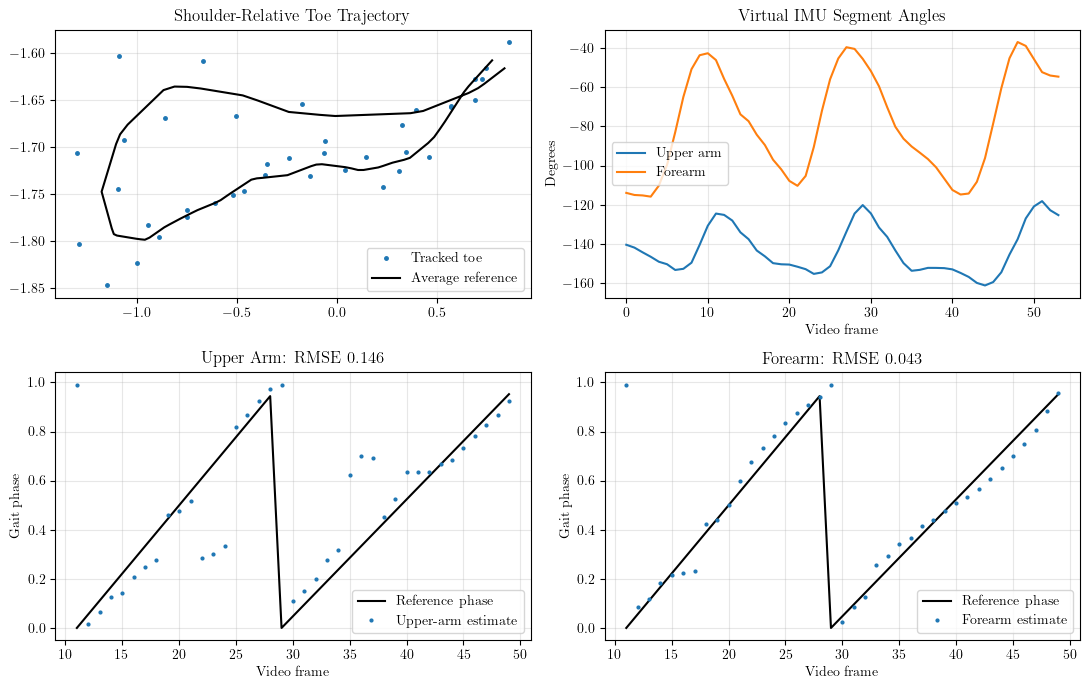

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

axes[0, 0].plot(toe[frame_ids, 0], toe[frame_ids, 1], '.', ms=5,
                label="Tracked toe")
axes[0, 0].plot(x_ref, y_ref, color="black", label="Average reference")
axes[0, 0].set_title("Shoulder-Relative Toe Trajectory")
axes[0, 0].set_aspect('auto')
axes[0, 0].legend()

axes[0, 1].plot(frames, np.rad2deg(upper_angle), label="Upper arm")
axes[0, 1].plot(frames, np.rad2deg(fore_angle), label="Forearm")
axes[0, 1].set(title="Virtual IMU Segment Angles", xlabel="Video frame", ylabel="Degrees")
axes[0, 1].legend()

axes[1, 0].plot(frame_ids, s_left_true, color="black", label="Reference phase")
axes[1, 0].plot(frame_ids, s_upper, '.', ms=4, label="Upper-arm estimate")
axes[1, 0].set(title=f"Upper Arm: RMSE {phase_rmse(s_upper):.3f}",
               xlabel="Video frame", ylabel="Gait phase")
axes[1, 0].legend()

axes[1, 1].plot(frame_ids, s_left_true, color="black", label="Reference phase")
axes[1, 1].plot(frame_ids, s_fore, '.', ms=4, label="Forearm estimate")
axes[1, 1].set(title=f"Forearm: RMSE {phase_rmse(s_fore):.3f}",
               xlabel="Video frame", ylabel="Gait phase")
axes[1, 1].legend()

for ax in axes.flat:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("gait_imu_diagnostics.png", dpi=150)
plt.show()

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.3), sharex=True, sharey=True)
reach = L1 + L2 + L3
floor = np.percentile(toe[frame_ids, 1], 10)  # illustrative ground guide

artists = []
for ax, title in zip(axes, ["Upper-arm virtual IMU", "Forearm virtual IMU"]):
    ax.set(xlim=(-1.75, 1.25), ylim=(-2.15, 0.15), title=title)
    ax.set_aspect("equal")
    ax.grid(alpha=0.25)
    ax.axhline(floor, ls="--", color="gray", alpha=0.6)
    left_line, = ax.plot([], [], "o-", color="red", lw=2.5, ms=5,
                         label="Left: measured")
    right_line, = ax.plot([], [], "o-", color="blue", lw=2.5, ms=5,
                          label="Right: predicted")
    reference_line, = ax.plot([], [], "--", color="black", lw=1.2,
                              alpha=0.6, label="Right: shifted reference")
    ax.legend(loc="lower right", fontsize=8)
    artists.append((left_line, right_line, reference_line))

def leg_points(angles, frame):
    sx, sy, ex, ey, wx, wy, px, py = forward_kinematics_3link(
        angles[0][frame], angles[1][frame], angles[2][frame], L1, L2, L3)
    return [sx, ex, wx, px], [sy, ey, wy, py]

def update(i):
    source = frame_ids[i]
    measured = ([0, elbow[source, 0], wrist[source, 0], toe[source, 0]],
                [0, elbow[source, 1], wrist[source, 1], toe[source, 1]])
    output = []
    for angles, (left_line, right_line, ref_line) in zip(
        [right_upper, right_fore], artists):
        left_line.set_data(*measured)
        right_line.set_data(*leg_points(angles, i))
        ref_line.set_data(*leg_points(right_true, i))
        output += [left_line, right_line, ref_line]
    return output

plt.tight_layout()
anim = FuncAnimation(fig, update, frames=n_frames,
                     interval=1000/fps, blit=True, repeat=True)
plt.close(fig)
HTML(anim.to_jshtml())

In [8]:
anim.save("dog_gait_imu_comparison.gif", writer=PillowWriter(fps=fps))